# Analisis Operasi Point Operation pada Citra Digital

Tujuan

1. Membaca dan menampilkan citra digital.
2. Menerapkan operasi kecerahan dan kontras pada setiap piksel.
3. Membandingkan citra asli dengan hasil pengolahan.
4. Mengamati perubahan distribusi intensitas melalui histogram.
5. Membandingkan rata-rata intensitas, standar deviasi, dan entropi.


## 1. Dasar teori

Point Operation adalah operasi yang menghitung nilai piksel keluaran berdasarkan nilai piksel masukan pada posisi yang sama. Operasi ini tidak memerlukan nilai piksel tetangga.

### Operasi kecerahan (*brightness*)

\[
g(x,y)=f(x,y)+b
\]

`b` adalah nilai perubahan kecerahan. Nilai positif membuat citra lebih terang dan nilai negatif membuatnya lebih gelap.

### Operasi kontras (*contrast*)

\[
g(x,y)=\alpha(f(x,y)-128)+128
\]

`α` adalah faktor kontras. Jika `α > 1`, perbedaan intensitas diperbesar; jika `0 < α < 1`, perbedaan intensitas diperkecil. Angka 128 adalah titik tengah rentang intensitas 8-bit (0–255).

Setelah perhitungan, nilai piksel dibatasi pada rentang 0–255. Pembatasan ini diperlukan karena nilai di luar rentang tersebut tidak dapat direpresentasikan sebagai intensitas 8-bit.

## 2. Persiapan library

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

plt.rcParams["figure.dpi"] = 100
print("Library berhasil diimpor.")

Library berhasil diimpor.


## 3. Membaca citra asli

Foto dibuka menggunakan Pillow lalu dikonversi menjadi RGB. Array NumPy memudahkan program melakukan perhitungan terhadap nilai piksel. Foto harus berada di folder yang sama dengan notebook, kecuali kamu menuliskan path foldernya.

Ukuran array (tinggi, lebar, kanal): (981, 736, 3)
Tipe data: uint8
Nilai piksel minimum: 0
Nilai piksel maksimum: 255


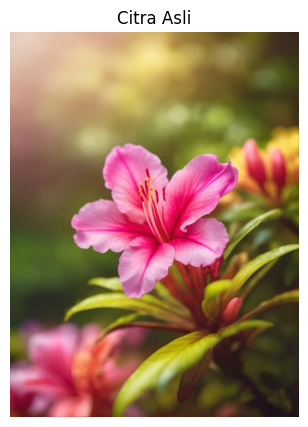

In [12]:
IMG_PATH = "Gambar Bunga.jpg"  

if not Path(IMG_PATH).exists():
    raise FileNotFoundError(
        f"File '{IMG_PATH}' tidak ditemukan. Letakkan foto di folder notebook "
        "atau ubah IMG_PATH sesuai lokasi file."
    )

citra = np.array(Image.open(IMG_PATH).convert("RGB"))

print("Ukuran array (tinggi, lebar, kanal):", citra.shape)
print("Tipe data:", citra.dtype)
print("Nilai piksel minimum:", citra.min())
print("Nilai piksel maksimum:", citra.max())

plt.figure(figsize=(7, 5))
plt.imshow(citra)
plt.title("Citra Asli")
plt.axis("off")
plt.show()

## 4. Fungsi Point Operation

Fungsi berikut menjalankan perubahan kecerahan terlebih dahulu, kemudian perubahan kontras. Data sementara menggunakan `float32` agar perhitungan tidak mengalami masalah tipe bilangan bulat. `np.clip` menjaga nilai tetap pada rentang 0–255.

In [13]:
def point_operation(citra, brightness=0, contrast=1.0):
    hasil = citra.astype(np.float32)

    # Mengubah kecerahan
    hasil = hasil + brightness

    # Mengubah kontras terhadap titik tengah 128
    hasil = (hasil - 128) * contrast + 128

    # Membatasi intensitas ke rentang citra 8-bit
    hasil = np.clip(hasil, 0, 255)

    return hasil.astype(np.uint8)

## 5. Eksperimen 1: perubahan kecerahan

Pada eksperimen ini, kecerahan diubah dengan nilai +50 dan -50. Parameter kontras dibiarkan 1.0 sehingga tidak ada perubahan kontras tambahan.

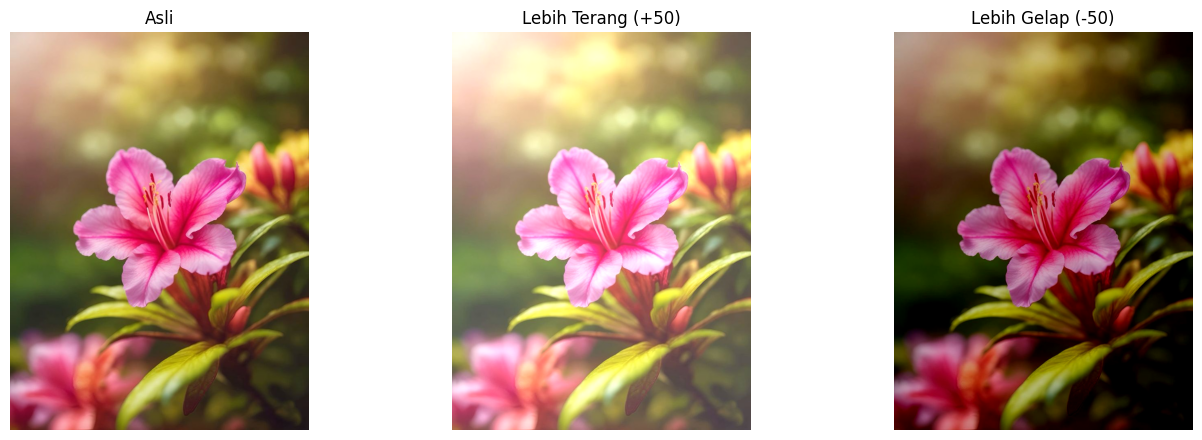

In [14]:
citra_terang = point_operation(citra, brightness=50, contrast=1.0)
citra_gelap = point_operation(citra, brightness=-50, contrast=1.0)

fig, ax = plt.subplots(1, 3, figsize=(14, 4.5))
for a, gambar, judul in zip(
    ax,
    [citra, citra_terang, citra_gelap],
    ["Asli", "Lebih Terang (+50)", "Lebih Gelap (-50)"]
):
    a.imshow(gambar)
    a.set_title(judul)
    a.axis("off")
plt.tight_layout()
plt.show()

### Histogram kecerahan

Histogram menunjukkan jumlah piksel pada tiap tingkat intensitas. Sumbu horizontal menunjukkan intensitas 0–255, sedangkan sumbu vertikal menunjukkan jumlah piksel. Ketika citra dibuat lebih terang, distribusi umumnya bergeser ke kanan; ketika dibuat lebih gelap, distribusi umumnya bergeser ke kiri. Bagian yang mencapai 0 atau 255 dapat menandakan detail gelap/terang yang terpotong (*clipping*).

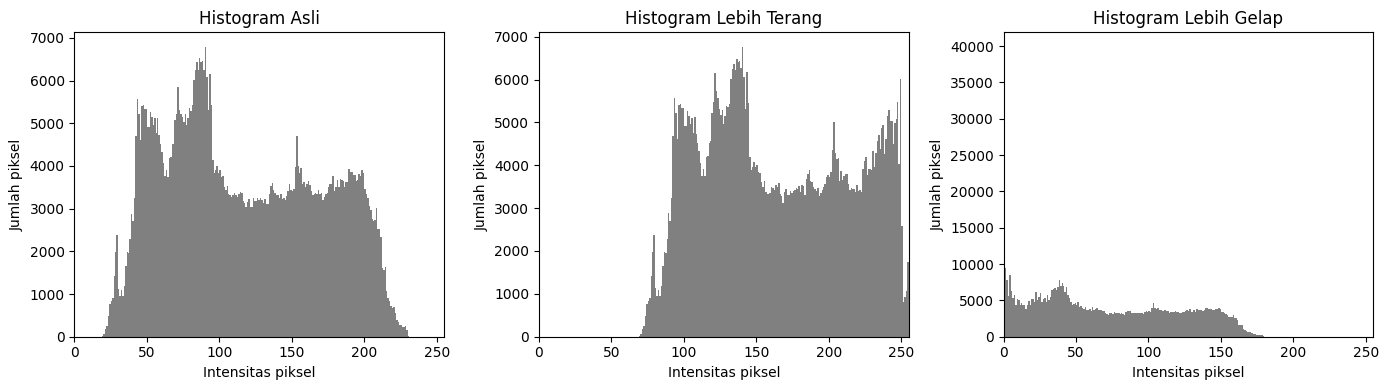

In [15]:
def keabuan(rgb):
    # Konversi RGB ke intensitas grayscale untuk analisis histogram
    return np.round(
        0.299 * rgb[:, :, 0] +
        0.587 * rgb[:, :, 1] +
        0.114 * rgb[:, :, 2]
    ).astype(np.uint8)

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, gambar, judul in zip(
    ax,
    [citra, citra_terang, citra_gelap],
    ["Histogram Asli", "Histogram Lebih Terang", "Histogram Lebih Gelap"]
):
    a.hist(keabuan(gambar).ravel(), bins=256, range=(0, 256), color="gray")
    a.set_title(judul)
    a.set_xlim(0, 255)
    a.set_xlabel("Intensitas piksel")
    a.set_ylabel("Jumlah piksel")
plt.tight_layout()
plt.show()

### Pengamatan kecerahan

Amati apakah histogram hasil bergeser ke kanan atau kiri dibandingkan histogram asli. Kecerahan yang terlalu tinggi dapat membuat area terang kehilangan detail, sedangkan kecerahan terlalu rendah dapat menyatukan detail di area gelap. Pengamatan akhir perlu disesuaikan dengan foto yang digunakan.

## 6. Eksperimen 2: perubahan kontras

Eksperimen ini menggunakan faktor kontras 1.5 (kontras tinggi) dan 0.5 (kontras rendah). Kecerahan tambahan diatur ke 0.

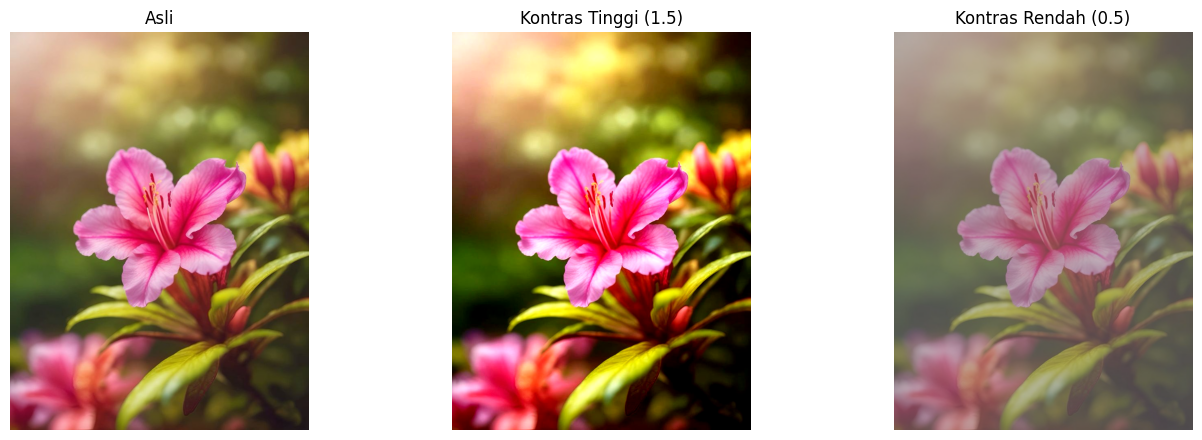

In [16]:
citra_kontras_tinggi = point_operation(citra, brightness=0, contrast=1.5)
citra_kontras_rendah = point_operation(citra, brightness=0, contrast=0.5)

fig, ax = plt.subplots(1, 3, figsize=(14, 4.5))
for a, gambar, judul in zip(
    ax,
    [citra, citra_kontras_tinggi, citra_kontras_rendah],
    ["Asli", "Kontras Tinggi (1.5)", "Kontras Rendah (0.5)"]
):
    a.imshow(gambar)
    a.set_title(judul)
    a.axis("off")
plt.tight_layout()
plt.show()

### Histogram kontras

Kontras tinggi cenderung menyebarkan intensitas menjauhi titik tengah, sedangkan kontras rendah cenderung mengumpulkan intensitas mendekati titik tengah. Efek persisnya bergantung pada distribusi piksel citra asli dan pembatasan nilai 0–255.

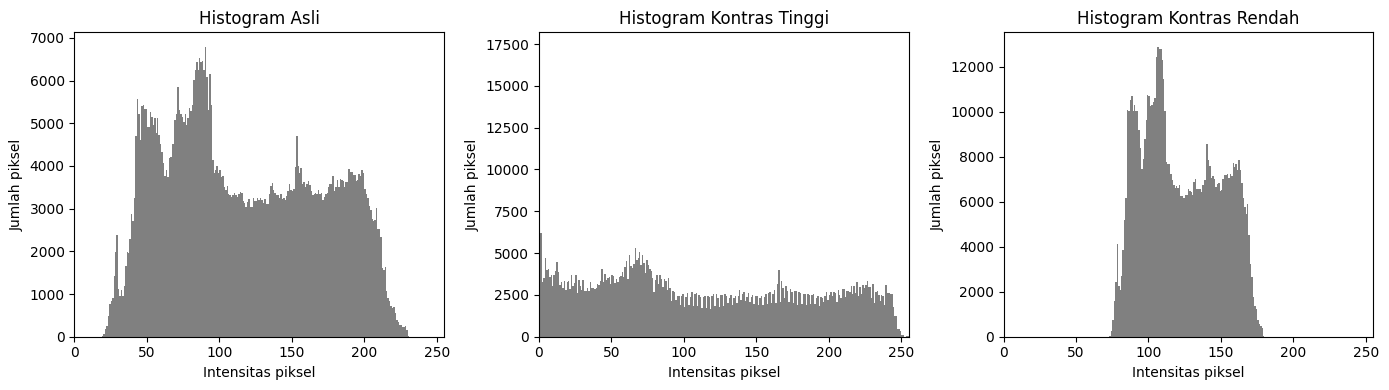

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, gambar, judul in zip(
    ax,
    [citra, citra_kontras_tinggi, citra_kontras_rendah],
    ["Histogram Asli", "Histogram Kontras Tinggi", "Histogram Kontras Rendah"]
):
    a.hist(keabuan(gambar).ravel(), bins=256, range=(0, 256), color="gray")
    a.set_title(judul)
    a.set_xlim(0, 255)
    a.set_xlabel("Intensitas piksel")
    a.set_ylabel("Jumlah piksel")
plt.tight_layout()
plt.show()

## 7. Metrik pengukuran

Metrik berikut dipakai untuk membantu membandingkan hasil secara numerik:

- **Rata-rata intensitas:** gambaran tingkat terang citra grayscale.
- **Standar deviasi:** menunjukkan seberapa menyebar intensitas; sering dipakai sebagai indikasi kontras.
- **Entropi Shannon:** mengukur keragaman distribusi intensitas. Nilai lebih tinggi tidak selalu berarti citra lebih baik, karena noise juga dapat menambah keragaman.

Metrik ini bersifat pendukung dan tidak menggantikan pemeriksaan visual.

In [18]:
def entropi_shannon(gray):
    histogram = np.bincount(gray.ravel(), minlength=256).astype(float)
    probabilitas = histogram / histogram.sum()
    probabilitas = probabilitas[probabilitas > 0]
    return -np.sum(probabilitas * np.log2(probabilitas))

def hitung_metrik(rgb, nama):
    gray = keabuan(rgb)
    return {
        "Citra": nama,
        "Rata-rata intensitas": gray.mean(),
        "Standar deviasi": gray.std(),
        "Entropi (bit)": entropi_shannon(gray)
    }

citra_hasil = [
    ("Asli", citra),
    ("Lebih terang", citra_terang),
    ("Lebih gelap", citra_gelap),
    ("Kontras tinggi", citra_kontras_tinggi),
    ("Kontras rendah", citra_kontras_rendah),
]

tabel_metrik = pd.DataFrame(
    [hitung_metrik(gambar, nama) for nama, gambar in citra_hasil]
).round(3)

tabel_metrik

,Citra,Rata-rata intensitas,Standar deviasi,Entropi (bit)
0,Asli,116.605,52.703,7.551
1,Lebih terang,164.209,49.934,7.427
2,Lebih gelap,69.256,49.997,7.246
3,Kontras tinggi,110.639,73.675,7.878
4,Kontras rendah,122.049,26.348,6.553


## 8. Rekapitulasi hasil

Tabel ini merangkum metrik dari semua citra yang dibandingkan.

In [19]:
tabel_metrik

,Citra,Rata-rata intensitas,Standar deviasi,Entropi (bit)
0,Asli,116.605,52.703,7.551
1,Lebih terang,164.209,49.934,7.427
2,Lebih gelap,69.256,49.997,7.246
3,Kontras tinggi,110.639,73.675,7.878
4,Kontras rendah,122.049,26.348,6.553


## 9. Menyimpan hasil citra

Hasil disimpan dalam format PNG agar tidak terkena kompresi JPEG tambahan. File akan tersimpan di folder kerja notebook.

In [20]:
nama_file = {
    "lebih_terang": citra_terang,
    "lebih_gelap": citra_gelap,
    "kontras_tinggi": citra_kontras_tinggi,
    "kontras_rendah": citra_kontras_rendah,
}

for nama, gambar in nama_file.items():
    Image.fromarray(gambar).save(f"hasil_{nama}.png")

print("Hasil pengolahan berhasil disimpan.")

Hasil pengolahan berhasil disimpan.


## 10. Kesimpulan

Lengkapi kesimpulan ini setelah mengamati output:

1. Point Operation mengubah nilai intensitas piksel berdasarkan operasi matematis pada piksel tersebut.
2. Penambahan kecerahan membuat intensitas bertambah, sedangkan pengurangan kecerahan membuat intensitas berkurang.
3. Faktor kontras di atas 1 memperbesar perbedaan intensitas, sementara faktor antara 0 dan 1 mengurangi perbedaan intensitas.
4. Histogram menunjukkan bagaimana distribusi intensitas berubah setelah pengolahan.
5. Metrik dan bar chart mendukung analisis, tetapi hasil terbaik tetap perlu ditentukan dengan melihat citra dan tujuan pengolahannya.

**Keterbatasan:** hasil dipengaruhi foto masukan, nilai parameter, dan clipping pada intensitas 0–255. Notebook ini merupakan demonstrasi dasar, bukan metode peningkatan citra yang selalu menghasilkan kualitas terbaik untuk semua foto.